Solución de referencia en CVXPY

In [1]:
%pip -q install cvxpy

import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=8, suppress=True)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
m = 5
counts = np.array([500., 300., 200., 0., 0.])
N = counts.sum()
mu0 = np.array([0.35, 0.35, 0.30, 0.0, 0.0])
Sigma0 = 0.0025 * np.eye(m)
Q = np.linalg.inv(Sigma0)
positive_count = counts > 0

def objective(p):
    p = np.asarray(p)
    if np.any(p[positive_count] <= 0):
        return np.inf
    likelihood = -counts[positive_count] @ np.log(p[positive_count])
    d = p - mu0
    return likelihood + 0.5 * d @ Q @ d

def gradient(p):
    g = Q @ (p - mu0)
    g[positive_count] -= counts[positive_count] / p[positive_count]
    return g

def fbar(p):
    return objective(p) / N

def gradbar(p):
    return gradient(p) / N

print("Counts:", counts, "  N =", N)
print("Prior mean:", mu0)

Counts: [500. 300. 200.   0.   0.]   N = 1000.0
Prior mean: [0.35 0.35 0.3  0.   0.  ]


In [3]:
p_var = cp.Variable(m)
likelihood = cp.sum(cp.multiply(counts[positive_count],
                                -cp.log(p_var[np.where(positive_count)[0]])))
d = p_var - mu0
cvx_objective = cp.Minimize((likelihood + 0.5 * cp.quad_form(d, Q))/N)
cvx_constraints = [cp.sum(p_var) == 1, p_var >= 0,
                   p_var[:3] >= 1e-10]
cvx_problem = cp.Problem(cvx_objective, cvx_constraints)
cvx_problem.solve(solver="CLARABEL")
if cvx_problem.status not in ("optimal", "optimal_inaccurate"):
    raise RuntimeError(f"CVXPY failed: {cvx_problem.status}")

p_ref = np.asarray(p_var.value).ravel()
nu_ref = float(cvx_constraints[0].dual_value)
lambda_ref = np.asarray(cvx_constraints[1].dual_value).ravel()

print("CVXPY status:", cvx_problem.status)
print("Reference p*:", p_ref)
print("F(p*):", objective(p_ref))
print("Equality multiplier (CVXPY convention):", nu_ref)
print("Nonnegativity multipliers:", lambda_ref)
print("Complementarity lambda*p:", lambda_ref * p_ref)

CVXPY status: optimal
Reference p*: [ 0.48086166  0.30894903  0.21018932 -0.         -0.        ]
F(p*): 1035.7860393346614
Equality multiplier (CVXPY convention): 0.9874093161591373
Nonnegativity multipliers: [0.00000001 0.00000001 0.00000001 0.98740932 0.98740932]
Complementarity lambda*p: [ 0.  0.  0. -0. -0.]


## Método de gradiente primal–dual

In [4]:
def primal_dual_gradient(iterations=50000, tau=0.01, sigma=0.01):
    p = np.array([0.30, 0.30, 0.30, 0.05, 0.05])
    lam = np.zeros(m)
    nu = 0.0
    hist = []
    hist_xul=[]
    for k in range(iterations):
        grad_L = gradbar(p) + nu*np.ones(m) - lam
        p = p - tau*grad_L
        # Domain safeguard only: keep coordinates inside log domain.
        p[:3] = np.maximum(p[:3], 1e-10)

        nu += sigma * (p.sum() - 1.0)
        lam = np.maximum(0.0, lam - sigma*p)

        if k % 100 == 0:
            
            hist_xul.append([np.linalg.norm(p-p_ref),np.linalg.norm(lam-lambda_ref),np.linalg.norm(nu-nu_ref)])
            hist.append([np.linalg.norm(p-p_ref), abs(p.sum()-1),
                        np.linalg.norm(lam*p), lam[3], lam[4]])
    return p, lam, nu, np.asarray(hist),np.asarray(hist_xul)

p_pd, lambda_pd, nu_pd, pd_history ,my_hist= primal_dual_gradient()
print("Primal-dual p:", p_pd)
print("Distance to CVXPY:", np.linalg.norm(p_pd-p_ref))
print("Simplex residual:", abs(p_pd.sum()-1))
print("Complementarity residual:", np.linalg.norm(lambda_pd*p_pd))
print("Dual multipliers:", lambda_pd)

Primal-dual p: [ 0.48086252  0.30894934  0.21018814 -0.         -0.        ]
Distance to CVXPY: 1.495490305409213e-06
Simplex residual: 3.9968028886505635e-15
Complementarity residual: 6.396027179362142e-15
Dual multipliers: [0.         0.         0.         0.98745323 0.98745323]


1.4

In [5]:
        
        
        #p = p - tau*grad_L    / p es mi x,  

        #nu += sigma * (p.sum() - 1.0)  /este es mi  lambda
        #lam = np.maximum(0.0, lam - sigma*p)  / este  es mi mu  []+ es lo mismo que  hae el  maximo  ener mu nuevo  y 0
        #sigma es  mi alfa

1.5

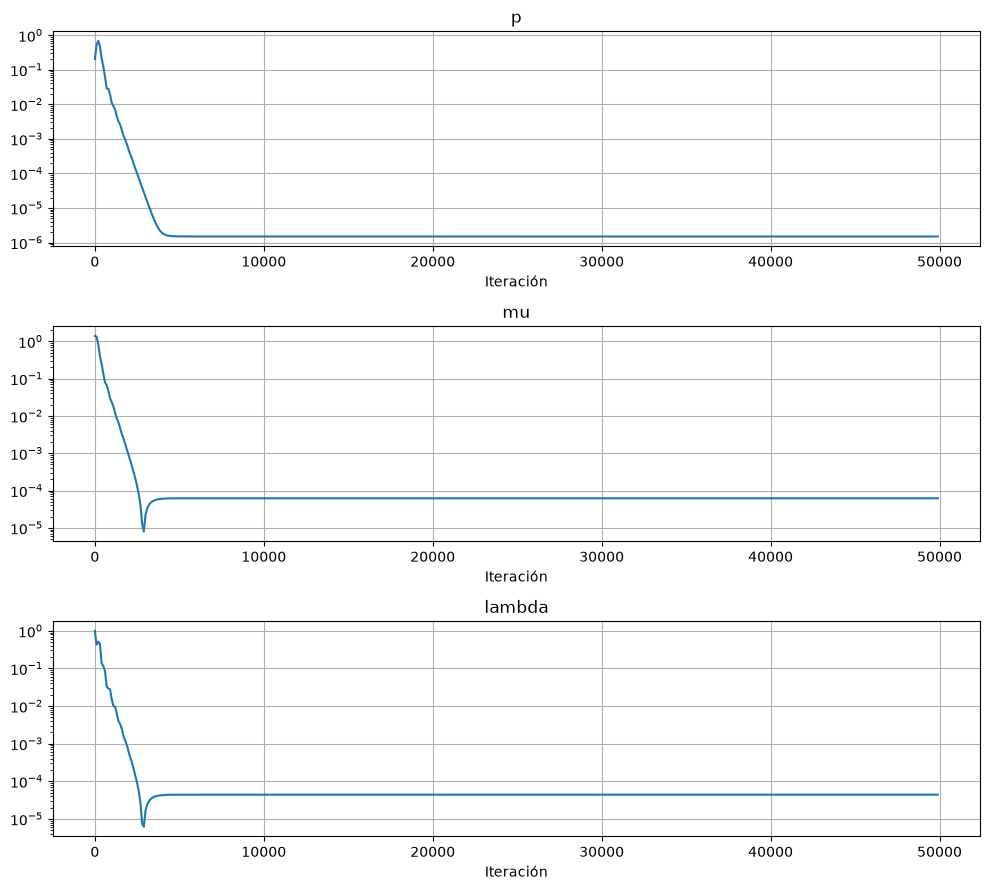

1.495490305409213e-06
6.210536691089066e-05
4.391629734989966e-05


In [6]:
x = np.arange(len(my_hist)) * 100

fig, axs = plt.subplots(3, 1, figsize=(10, 9))

axs[0].semilogy(x, my_hist[:, 0])
axs[0].set_title(r"p")

axs[1].semilogy(x, my_hist[:, 1])
axs[1].set_title("mu")

axs[2].semilogy(x, my_hist[:, 2])
axs[2].set_title("lambda")

for ax in axs:
    ax.set_xlabel("Iteración")
    ax.grid(True)

plt.tight_layout()
plt.show()

print(my_hist[-1, 0])
print(my_hist[-1, 1])
print(my_hist[-1, 2])

## 5. Método de Punto Interior

In [7]:

def solve_barrier_path(t_values, newton_tol=1e-10,
                       max_newton=100, beta=0.5, alpha=0.01):

    p = np.full(m, 1/m)
    path = []
    iterations=[]
    for t in t_values:

        def obj(x):
            if np.any(x <= 0):
                return np.inf
            return fbar(x) - np.log(x).sum()/t

        def jac(x):
            return gradbar(x) - 1.0/(t*x)

        def hess(x):
            # Hessian of the original normalized objective
            H = Q/N + np.diag(
                counts/(N*x**2)
            )
            # Barrier Hessian
            H += np.diag(1.0/(t*x**2))
            return H
       
        for iteration in range(max_newton):
    
            g = jac(p)
            H = hess(p)

            # Equality-constrained Newton KKT system
            KKT = np.block([
                [H, np.ones((m,1))],
                [np.ones((1,m)), np.zeros((1,1))]
            ])

            rhs = np.concatenate([-g, [0.0]])

            solution = np.linalg.solve(KKT, rhs)
            delta = solution[:m]

            # Newton decrement squared
            decrement_sq = -g @ delta

            if decrement_sq/2 <= newton_tol:
                break

            # Backtracking line search
            step = 1.0
            f_current = obj(p)

            while True:
                p_new = p + step*delta

                # Maintain strict positivity
                if np.all(p_new > 0):
                    f_new = obj(p_new)

                    if f_new <= f_current + alpha*step*(g @ delta):
                        break

                step *= beta

                if step < 1e-14:
                    raise RuntimeError(
                        f"Line search failed at t={t}"
                    )

            p = p_new

        else:
            print(f"Newton warning at t={t}: "
                  f"maximum iterations reached")
        #2.4------------------------------------
        # Barrier-induced inequality multipliers
        lam_t = 1.0/(t*p) #mu   

        # Primal objective error
        primal_error = fbar(p) - fbar(p_ref)#f(xt)-f(x*)
        
        # Complementarity gap
        complementarity_gap = float(lam_t @ p)#   λt⊤.pt
        #--------------------------------------
        
        path.append((
            t, p.copy(), primal_error,
            complementarity_gap, m/t, lam_t.copy()
        ))
        iterations.append(iteration+1)
        print(
            f"t={t:9.1f}, Newton iterations={iteration+1:3d}, "
            f"decrement={decrement_sq/2:.2e}, "
            f"gap={complementarity_gap:.3e}, "
            f"bound={m/t:.3e}"
        )

    return path,iterations


t_values = np.logspace(1, 5, 15)
ip_path ,_= solve_barrier_path(t_values)

for t, p, err, gap, bound, lam in ip_path[::4]:
    print(
        f"t={t:9.1f}, objective error={err:.3e}, "
        f" λt⊤.pt:{gap:.3e}, "
        f"m/t={bound:.3e}, "
        f"tail mass={p[3]+p[4]:.3e}"
    )



t=     10.0, Newton iterations=  6, decrement=2.75e-13, gap=5.000e-01, bound=5.000e-01
t=     19.3, Newton iterations=  5, decrement=2.09e-11, gap=2.590e-01, bound=2.590e-01
t=     37.3, Newton iterations=  6, decrement=2.42e-14, gap=1.341e-01, bound=1.341e-01
t=     72.0, Newton iterations=  5, decrement=-1.47e-17, gap=6.947e-02, bound=6.947e-02
t=    138.9, Newton iterations=  4, decrement=1.46e-11, gap=3.598e-02, bound=3.598e-02
t=    268.3, Newton iterations=  4, decrement=7.40e-13, gap=1.864e-02, bound=1.864e-02
t=    517.9, Newton iterations=  4, decrement=5.71e-14, gap=9.653e-03, bound=9.653e-03
t=   1000.0, Newton iterations=  4, decrement=7.88e-15, gap=5.000e-03, bound=5.000e-03
t=   1930.7, Newton iterations=  4, decrement=1.65e-15, gap=2.590e-03, bound=2.590e-03
t=   3727.6, Newton iterations=  4, decrement=5.92e-16, gap=1.341e-03, bound=1.341e-03
t=   7196.9, Newton iterations=  4, decrement=3.45e-16, gap=6.947e-04, bound=6.947e-04
t=  13895.0, Newton iterations=  3, decrem

2.5

t=      1.0, Newton iterations=  4, decrement=2.10e-15, gap=5.000e+00, bound=5.000e+00
t=      2.0, Newton iterations=  4, decrement=5.42e-17, gap=2.500e+00, bound=2.500e+00
t=      4.0, Newton iterations=  4, decrement=3.97e-13, gap=1.250e+00, bound=1.250e+00
t=      8.0, Newton iterations=  5, decrement=-8.05e-17, gap=6.250e-01, bound=6.250e-01
t=     16.0, Newton iterations=  5, decrement=7.66e-12, gap=3.125e-01, bound=3.125e-01
t=     32.0, Newton iterations=  6, decrement=5.63e-14, gap=1.562e-01, bound=1.562e-01
t=     64.0, Newton iterations=  5, decrement=-1.35e-16, gap=7.812e-02, bound=7.812e-02
t=    128.0, Newton iterations=  4, decrement=3.23e-12, gap=3.906e-02, bound=3.906e-02
t=    256.0, Newton iterations=  4, decrement=1.84e-14, gap=1.953e-02, bound=1.953e-02
t=    512.0, Newton iterations=  4, decrement=1.04e-16, gap=9.766e-03, bound=9.766e-03
t=   1024.0, Newton iterations=  3, decrement=1.28e-11, gap=4.883e-03, bound=4.883e-03
t=   2048.0, Newton iterations=  3, decre

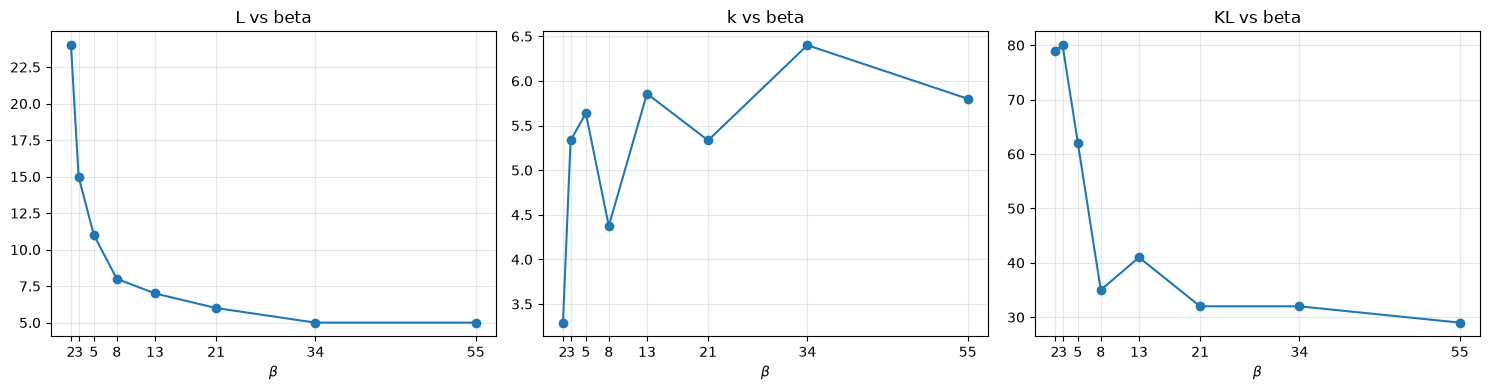

In [8]:
betas=[2,3,5,8,13,21,34,55] 
t0 = 1
tmax = 1e7
kls=[]
ks=[]
ls=[]
for b in betas:
    t_values=[]
    t_values.append(t0)
    while True:
        new_t=t_values[-1]*b
        if new_t<tmax:
            t_values.append(new_t)
        else:
            break

    
    _,k = solve_barrier_path(t_values)
    print(f"Beta:{b}")
    print(f"T steps:{len(t_values)}")
    print(f"Pasos newton:{k}")
    print(f"T:{t_values}")
    print(f"KL:{np.mean(np.array(k))*len(t_values)}")
    
    L = len(t_values)
    k_mean = np.mean(k)

    ls.append(L)
    ks.append(k_mean)
    kls.append(k_mean * L)



fig, axes = plt.subplots(1, 3, figsize=(15, 4))

data = [
    (ls, 'L vs beta', ''),
    (ks, 'k vs beta', ''),
    (kls, 'KL vs beta', '')
]

for ax, (values, title, ylabel) in zip(axes, data):
    ax.plot(betas, values, marker='o')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(betas)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

plt.show()    
    
 

## 6. Optimización distribuida con consenso via  ADMM

In [9]:
def project_simplex(v):
    u = np.sort(v)[::-1]
    cssv = np.cumsum(u)-1
    idx = np.arange(1, len(v)+1)
    rho = np.where(u-cssv/idx > 0)[0][-1]
    theta = cssv[rho]/(rho+1)
    return np.maximum(v-theta, 0.0)

def consensus_admm(K=4, iterations=100, rho=2.0):
    local_counts = np.zeros((K,m))
    for j, nj in enumerate(counts.astype(int)):
        q, r = divmod(nj,K) # separo los nj
        local_counts[:,j] = q
        local_counts[:r,j] += 1

    # CVXPY local optimization problems
    x_vars = []
    centers = []
    problems = []

    for k in range(K):
        x = cp.Variable(m, nonneg=True)
        center = cp.Parameter(m)

        nk = local_counts[k]
        posk = nk > 0

        objective = (
            -cp.sum(cp.multiply(nk[posk], cp.log(x[posk])))
            + 0.5/K * cp.quad_form(x-mu0, Q)
            + 0.5*rho * cp.sum_squares(x-center)
        )

        problem = cp.Problem(
            cp.Minimize(objective),
            [cp.sum(x) == 1, x >= 1e-10]
        )

        x_vars.append(x)
        centers.append(center)
        problems.append(problem)

    # ADMM initialization
    z = np.tile(np.full(m,1/m),(K,1))
    u = np.zeros_like(z)
    p = np.full(m,1/m)

    hist = []

    for it in range(iterations):

        # Local primal updates
        for k in range(K): #sepao por cada agente
            centers[k].value = p-u[k]

            problems[k].solve(
                solver=cp.CLARABEL,
                warm_start=True,
                tol_gap_abs=1e-9,
                tol_feas=1e-9,
                tol_gap_rel=1e-9
            )

            if problems[k].status not in (
                cp.OPTIMAL, cp.OPTIMAL_INACCURATE
            ):
                raise RuntimeError(
                    f"ADMM local problem {k} failed: "
                    f"{problems[k].status}"
                )

            z[k] = x_vars[k].value #z(k)r+1= argmin{fk(z) + rho 2 ∥z − p^^r + u r k∥ 2}

        # Consensus update
        p_old = p.copy()
        p = np.mean(z+u,axis=0)  #p^r+1 = 1/ K sum (z_(k) ^r+1  + u_(k)^r  )

        # Dual update
        u += z-p

        # Residuals
        r_primal = np.linalg.norm(z-p[None,:])
        r_primal = np.linalg.norm(z-p[None,:])
        r_dual = rho*np.sqrt(K)*np.linalg.norm(p-p_old)

 
        sumu = np.sum(u, axis=0) #en  punto  fijo deberria ser 0

        print(sumu)
        norm_sumu = np.linalg.norm(sumu)
        hist.append([
            r_primal,
            r_dual,
            np.linalg.norm(p-p_ref),
            norm_sumu
        ])

    return p,z,u,np.asarray(hist),local_counts

p_admm,z_admm,u_admm,admm_history,local_counts=consensus_admm()
print("ADMM estimate:",p_admm)
print("Distance to CVXPY:",np.linalg.norm(p_admm-p_ref))
print("Final consensus residual:",admm_history[-1,0])
print("Max agent-to-agent disagreement:",np.max(np.linalg.norm(z_admm-p_admm,axis=1)))
print("Dual scaled-variable sum (should be zero):",np.linalg.norm(u_admm.sum(axis=0)))

[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0

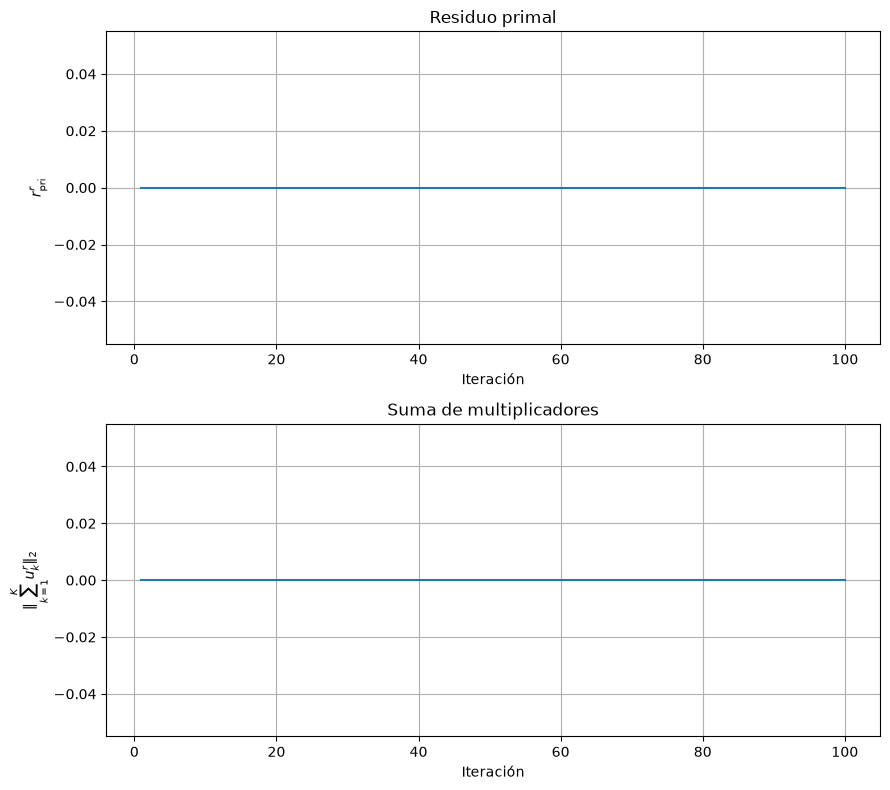

Residuo primal final: 0.0
Norma de la suma de mu: 0.0


In [10]:
iterations = np.arange(1, len(admm_history) + 1)

fig, axs = plt.subplots(2, 1, figsize=(9, 8))

# Residuo primal
axs[0].plot(iterations, admm_history[:, 0])
axs[0].set_title("Residuo primal")
axs[0].set_xlabel("Iteración")
axs[0].set_ylabel(r"$r_{\mathrm{pri}}^r$")
axs[0].grid(True)

# Norma de la suma de multiplicadores
axs[1].plot(iterations, admm_history[:, 3])
axs[1].set_title("Suma de multiplicadores")
axs[1].set_xlabel("Iteración")
axs[1].set_ylabel(r"$\|\sum_{k=1}^K u_k^r\|_2$")
axs[1].grid(True)

plt.tight_layout()
plt.show()

print("Residuo primal final:", admm_history[-1, 0])
print("Norma de la suma de mu:",
      admm_history[-1, 3])

## 7. Stochastic projected gradient

In [11]:
def online_projected_sgd(epochs=1200, eta0=0.001, t0=5000,
                         averaging_start=0.5, seed=11):
    rng=np.random.default_rng(seed)
    # Each epoch is a fresh bootstrap pass through the empirical distribution.
    T=int(epochs*N)
    observations=rng.choice(m,size=T,p=counts/N)
    p=np.full(m,1/m)
    path=[]
    avg=np.zeros(m); n_avg=0
    for t,j in enumerate(observations, start=1):
        G=Q@(p-mu0)/N
        G[j] -= 1.0/max(p[j],1e-10)
        eta=eta0/(1+t/t0)**0.6
        p=project_simplex(p-eta*G)  #SPGD 2.b
        if t > averaging_start*T:
            avg += p
            n_avg += 1
        if t % N == 0:
            path.append(p.copy())
    return p,avg/n_avg,np.asarray(path),observations

p_sgd_last,p_sgd,sgd_path,observations=online_projected_sgd()
print("Last stochastic iterate:",p_sgd_last)
print("Averaged late iterate:",p_sgd)
print("Distance of averaged iterate to CVXPY:",np.linalg.norm(p_sgd-p_ref))

Last stochastic iterate: [0.47053344 0.31510168 0.21436487 0.         0.        ]
Averaged late iterate: [0.4811846  0.30832035 0.21049505 0.         0.        ]
Distance of averaged iterate to CVXPY: 0.000770059855057648


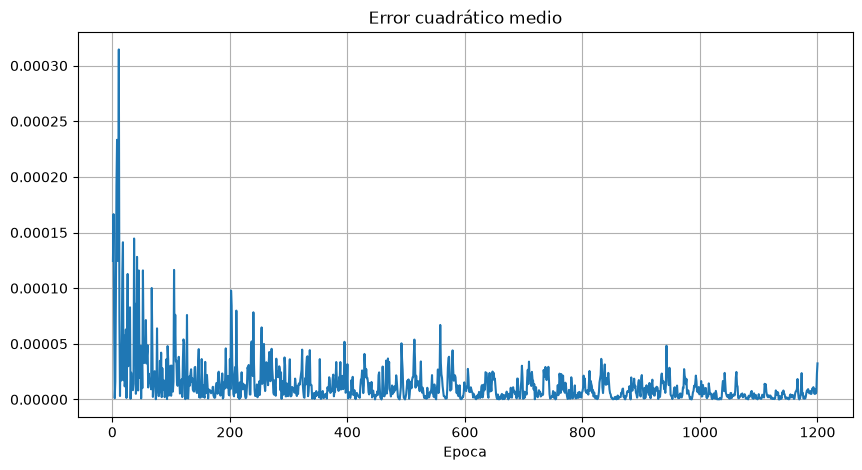

In [12]:
error = np.mean((sgd_path - p_ref)**2, axis=1)
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(error)+1), error)
plt.xlabel("Epoca")
plt.ylabel("")
plt.title("Error cuadrático medio")
plt.grid(True)
plt.show()